<a href="https://colab.research.google.com/github/SMC-AAU-CPH/ML-For-Beginners/blob/main/MLME_10_ANN_Keras_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workshop notebook 1: from perceptrons to transformers
**MED7 MLME, Session 10: Deep learning, transformers, GenAI, and towards world models**

This notebook follows the reading (Géron, *Hands-On ML*, ch. 10 to 12) and ends where notebook 2 (mini-LeAVJEPA) starts.

| Part | Topic | Reading | Time in class |
|---|---|---|---|
| A | ANNs with Scikit-Learn: perceptron, XOR, regression MLP, classification MLP | ch. 10, pp. 1 to 20 | 30 min |
| B | Deep neural networks with TensorFlow/Keras: Sequential, Functional, callbacks, modern defaults, GradientTape | ch. 10 to 12 | 60 min |
| C | Transformers and GenAI: attention from scratch, a tiny Vision Transformer, three generative objectives | beyond the reading | 90 min |

Cells marked **🧠 Predict** ask you to write down a guess *before* running. Cells marked **✍️ Exercise** are for pairs.

In [2]:
import numpy as np, matplotlib.pyplot as plt
import sklearn, tensorflow as tf
from tensorflow import keras
print("sklearn", sklearn.__version__, "| TF", tf.__version__, "| Keras", keras.__version__)
tf.random.set_seed(42); np.random.seed(42)

sklearn 1.6.1 | TF 2.21.0 | Keras 3.13.2


---
## Part A. ANNs with Scikit-Learn

### A1. The perceptron is a linear classifier
A threshold logic unit computes $h_{\mathbf w}(\mathbf x) = \mathrm{step}(\mathbf w^\top \mathbf x + b)$. Scikit-Learn's `Perceptron` is `SGDClassifier(loss="perceptron", learning_rate="constant", eta0=1, penalty=None)`.

In [3]:
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0)  # Iris setosa
per_clf = Perceptron(random_state=42).fit(X, y)
print(per_clf.predict([[2, 0.5], [3, 1]]))  # book: True, False

[ True False]


### A2. 🧠 Predict: can a perceptron learn XOR? Can an MLP?
Write your guess (yes/no, and for the MLP the *smallest* hidden layer you think works). Then run.

In [4]:
from sklearn.neural_network import MLPClassifier

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); y_xor = np.array([0, 1, 1, 0])
print("Perceptron:", Perceptron(max_iter=1000, random_state=0).fit(X_xor, y_xor).predict(X_xor))
for h in [1, 2, 4]:
    preds = [MLPClassifier(hidden_layer_sizes=(h,), activation="tanh", solver="lbfgs",
                           max_iter=2000, random_state=s).fit(X_xor, y_xor).predict(X_xor).tolist()
             for s in range(5)]
    print(f"MLP hidden={h}: solved in {sum(p == [0,1,1,0] for p in preds)}/5 random restarts")

Perceptron: [0 0 0 0]
MLP hidden=1: solved in 0/5 random restarts
MLP hidden=2: solved in 2/5 random restarts
MLP hidden=4: solved in 5/5 random restarts


**Take-away.** Two hidden units are enough in principle (Figure 10-6), but optimisation does not always find the solution. Wider layers make the loss landscape friendlier. This is one reason modern networks are over-parameterised.

### A3. Regression MLP (California housing, same data as Session 2)
Book recipe: scale inputs, ReLU hidden layers, no output activation, MSE loss.

In [5]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, random_state=42)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], early_stopping=True, random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
print("MLP valid RMSE:", root_mean_squared_error(y_valid, pipeline.predict(X_valid)))  # book: about 0.505

MLP valid RMSE: 0.5354701157001521


✍️ **Exercise A3 (3 min).** In Session 2 a `RandomForestRegressor` reached about 0.47 to 0.50 (in units of 100k USD) on this data. (a) Remove the `StandardScaler` and rerun: what happens and why? (b) Plot `mlp_reg.loss_curve_`. (c) Is a deep net the right tool for 8 tabular features? Argue in one sentence.

In [6]:
# your code here

### A4. Classification MLP (MNIST, same data as Session 3)
Book recipe for multiclass: softmax output, cross-entropy loss. `MLPClassifier` does this for you.

In [7]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", as_frame=False, parser="auto")
X_m, y_m = mnist.data[:20000] / 255.0, mnist.target[:20000]
X_m_tr, X_m_te, y_m_tr, y_m_te = X_m[:15000], X_m[15000:], y_m[:15000], y_m[15000:]

mlp_clf = MLPClassifier(hidden_layer_sizes=[256, 128], early_stopping=True, max_iter=50, random_state=42)
X_m_tr = np.asarray(X_m_tr, dtype=np.float32)
X_m_te = np.asarray(X_m_te, dtype=np.float32)
y_m_tr = np.asarray(y_m_tr, dtype=np.int64)
y_m_te = np.asarray(y_m_te, dtype=np.int64)

mlp_clf.fit(X_m_tr, y_m_tr)
print("MNIST test accuracy (15k training images):", mlp_clf.score(X_m_te, y_m_te))

MNIST test accuracy (15k training images): 0.9636


In Session 3 the `SGDClassifier` reached about 0.87 and a tuned `KNeighborsClassifier` about 0.97 on the full data. The MLP gets close with a fraction of the data and no feature engineering.

**Limits of Scikit-Learn MLPs:** no GPU, no custom layers, no custom losses, no attention. That is why we move to Keras.

---
## Part B. Deep neural networks with TensorFlow/Keras

### B1. Sequential API: an image classifier on Fashion MNIST (book pp. 23 to 40)

In [8]:
fashion = keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion
X_train, y_train = X_train_full[:-5000] / 255.0, y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:] / 255.0, y_train_full[-5000:]
X_test = X_test / 255.0
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

model = keras.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.summary()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

🧠 **Predict.** How many parameters does the first `Dense(300)` layer have? Compute it before reading `summary()`.

Epoch 1/10
1719/1719 - 15s - 9ms/step - accuracy: 0.7668 - loss: 0.7164 - val_accuracy: 0.8278 - val_loss: 0.5033
Epoch 2/10
1719/1719 - 3s - 2ms/step - accuracy: 0.8303 - loss: 0.4874 - val_accuracy: 0.8404 - val_loss: 0.4532
Epoch 3/10
1719/1719 - 3s - 2ms/step - accuracy: 0.8461 - loss: 0.4429 - val_accuracy: 0.8482 - val_loss: 0.4289
Epoch 4/10
1719/1719 - 3s - 2ms/step - accuracy: 0.8546 - loss: 0.4158 - val_accuracy: 0.8558 - val_loss: 0.4141
Epoch 5/10
1719/1719 - 3s - 2ms/step - accuracy: 0.8614 - loss: 0.3959 - val_accuracy: 0.8564 - val_loss: 0.4029
Epoch 6/10
1719/1719 - 3s - 2ms/step - accuracy: 0.8667 - loss: 0.3799 - val_accuracy: 0.8580 - val_loss: 0.3935
Epoch 7/10
1719/1719 - 3s - 2ms/step - accuracy: 0.8716 - loss: 0.3665 - val_accuracy: 0.8608 - val_loss: 0.3853
Epoch 8/10
1719/1719 - 3s - 2ms/step - accuracy: 0.8755 - loss: 0.3549 - val_accuracy: 0.8648 - val_loss: 0.3790
Epoch 9/10
1719/1719 - 3s - 2ms/step - accuracy: 0.8790 - loss: 0.3445 - val_accuracy: 0.8664 -

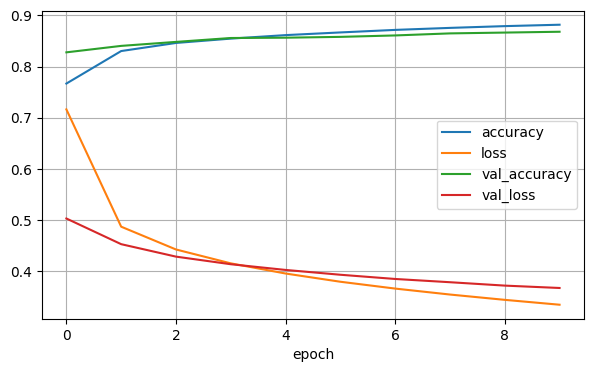

In [9]:
model.compile(loss="sparse_categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_valid, y_valid), verbose=2)
print("test:", model.evaluate(X_test, y_test, verbose=0))
import pandas as pd
pd.DataFrame(history.history).plot(figsize=(7, 4), grid=True, xlabel="epoch"); plt.show()

### B2. Functional API: a Wide & Deep regression MLP (book pp. 44 to 50)
The Functional API lets a graph have several paths. LeAVJEPA uses the same idea: two inputs (audio, video) feeding one network.

In [10]:
# Same housing splits as A3, kept under new names
Xh_full, Xh_test, yh_full, yh_test = train_test_split(housing.data, housing.target, random_state=42)
Xh_tr, Xh_va, yh_tr, yh_va = train_test_split(Xh_full, yh_full, random_state=42)

norm = keras.layers.Normalization()
inp = keras.layers.Input(shape=Xh_tr.shape[1:])
x = norm(inp)
deep = keras.layers.Dense(30, activation="relu")(x)
deep = keras.layers.Dense(30, activation="relu")(deep)
concat = keras.layers.Concatenate()([x, deep])          # wide path + deep path
out = keras.layers.Dense(1)(concat)
wide_deep = keras.Model(inputs=[inp], outputs=[out])

norm.adapt(Xh_tr)
wide_deep.compile(loss="mse", optimizer=keras.optimizers.Adam(1e-3), metrics=["RootMeanSquaredError"])
early = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
wide_deep.fit(Xh_tr, yh_tr, epochs=60, validation_data=(Xh_va, yh_va), callbacks=[early], verbose=0)
print("Wide & Deep valid RMSE:", wide_deep.evaluate(Xh_va, yh_va, verbose=0)[1])

Wide & Deep valid RMSE: 1.0242925882339478


In [11]:
""" from IPython.display import Image, display
# install pydot (`pip install pydot`) for `plot_model` to work.
import pydot
plot_path = keras.utils.plot_model(
    wide_deep, show_shapes=True, show_layer_names=True
)
display(Image(filename=plot_path)) """

' from IPython.display import Image, display\n# install pydot (`pip install pydot`) for `plot_model` to work.\nimport pydot\nplot_path = keras.utils.plot_model(\n    wide_deep, show_shapes=True, show_layer_names=True\n)\ndisplay(Image(filename=plot_path)) '

### B3. Modern defaults from chapter 11
The book's practical guidelines (Table 11-3): He initialization, a smooth ReLU variant (Swish/GELU), batch normalization, AdamW, dropout or early stopping. Transformers use GELU, LayerNorm and AdamW, so you will meet these again in notebook 2.

✍️ **Exercise B3 (4 min).** Replace the B1 model by a "modern" one using `kernel_initializer="he_normal"`, `activation="swish"`, a `BatchNormalization` layer after each hidden layer, `Dropout(0.2)` and `keras.optimizers.AdamW(1e-3)`. Train 10 epochs. Compare validation accuracy and the shape of the learning curves.

In [12]:
modern = keras.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    # your layers here
    keras.layers.Dense(10, activation="softmax"),
])

### B4. Chapter 12 in one cell: a custom training loop with `GradientTape`
`fit()` hides this loop. Self-supervised methods such as LeAVJEPA need custom losses computed from several forward passes, so you have to write the loop yourself. Notebook 2 does exactly this in PyTorch, where `loss.backward()` plays the role of `tape.gradient`.

In [13]:
small = keras.Sequential([keras.layers.Input(shape=[28, 28]), keras.layers.Flatten(),
                          keras.layers.Dense(100, activation="relu"), keras.layers.Dense(10)])
optimizer = keras.optimizers.AdamW(1e-3)
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
ds = tf.data.Dataset.from_tensor_slices((X_train.astype("float32"), y_train)).shuffle(10000).batch(64)

for epoch in range(2):
    for step, (xb, yb) in enumerate(ds):
        with tf.GradientTape() as tape:
            loss = loss_fn(yb, small(xb, training=True))
        grads = tape.gradient(loss, small.trainable_variables)        # reverse-mode autodiff
        optimizer.apply_gradients(zip(grads, small.trainable_variables))
    acc = np.mean(np.argmax(small(X_valid.astype("float32")), 1) == y_valid)
    print(f"epoch {epoch}: last batch loss {float(loss):.3f}, valid acc {acc:.3f}")

epoch 0: last batch loss 0.290, valid acc 0.853
epoch 1: last batch loss 0.168, valid acc 0.852


---
## Part C. Transformers and GenAI

### C1. Attention from scratch
Each token emits a **query** $\mathbf q$, a **key** $\mathbf k$ and a **value** $\mathbf v$. Attention is a soft dictionary lookup:
$$\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$
Every output token is a weighted average of all value vectors, with weights given by query-key similarity. Nothing in the formula depends on token order, so position must be added explicitly (positional embeddings).

🧠 **Predict.** Below, token 2 ("bark") has a query that points in the same direction as the key of token 0 ("dog"). Which row of the attention matrix will be most peaked, and where?

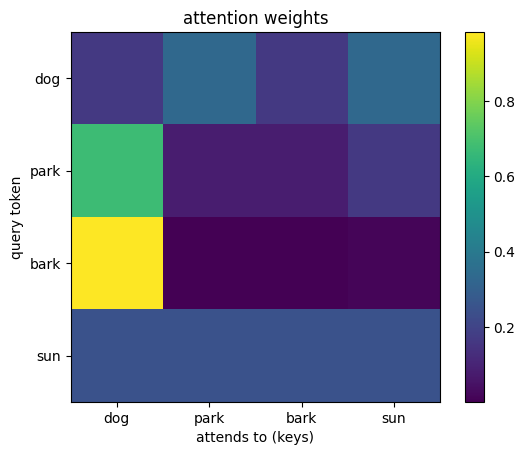

[[0.17 0.33 0.17 0.33]
 [0.67 0.08 0.08 0.16]
 [0.98 0.   0.   0.01]
 [0.25 0.25 0.25 0.25]]


In [14]:
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True); e = np.exp(z); return e / e.sum(axis=axis, keepdims=True)

tokens = ["dog", "park", "bark", "sun"]
K = np.array([[3., 0], [0, 1], [0, 0], [1, 1]])     # keys
Q = np.array([[0., 1], [1, 0], [3, 0], [0, 0]])     # queries
V = np.eye(4)                                       # values: one-hot, so the output shows the mixing weights
A = softmax(Q @ K.T / np.sqrt(K.shape[1]))
out = A @ V
plt.imshow(A, cmap="viridis"); plt.xticks(range(4), tokens); plt.yticks(range(4), tokens)
plt.xlabel("attends to (keys)"); plt.ylabel("query token"); plt.colorbar(); plt.title("attention weights"); plt.show()
print(np.round(A, 2))

✍️ **Exercise C1 (3 min, paper and pen).** Compute row "sun" by hand. Why is it uniform? What does scaling by $\sqrt{d_k}$ protect against when $d_k = 768$ (ViT-B)?

### C2. A tiny Vision Transformer in Keras
A ViT cuts the image into patches, linearly embeds each patch (a strided convolution does this), prepends a learnable `[CLS]` token, adds positional embeddings and runs transformer blocks: `x = x + MHA(LN(x)); x = x + MLP(LN(x))`. LeAVJEPA's `transformer.py` is exactly this block, and its `fusion.py` does the same patching for spectrograms (2D conv) and video (3D conv).

In [15]:
class ClsAndPosition(keras.layers.Layer):
    # Prepends a learnable [CLS] token and adds learnable positional embeddings.
    def build(self, input_shape):
        n, d = input_shape[1], input_shape[2]
        self.cls = self.add_weight(shape=(1, 1, d), initializer="random_normal", name="cls")
        self.pos = self.add_weight(shape=(1, n + 1, d), initializer="random_normal", name="pos")
    def call(self, x):
        b = keras.ops.shape(x)[0]
        cls = keras.ops.broadcast_to(self.cls, (b, 1, keras.ops.shape(x)[2]))
        return keras.ops.concatenate([cls, x], axis=1) + self.pos

def transformer_block(x, dim, heads, mlp_dim):
    h = keras.layers.LayerNormalization()(x)
    x = x + keras.layers.MultiHeadAttention(num_heads=heads, key_dim=dim // heads)(h, h)
    h = keras.layers.LayerNormalization()(x)
    h = keras.layers.Dense(mlp_dim, activation="gelu")(h)
    return x + keras.layers.Dense(dim)(h)

DIM = 64
inp = keras.layers.Input(shape=[28, 28, 1])
x = keras.layers.Conv2D(DIM, kernel_size=7, strides=7)(inp)    # 4x4 = 16 patches of 7x7 pixels
x = keras.layers.Reshape((16, DIM))(x)
x = ClsAndPosition()(x)                                        # 17 tokens
for _ in range(2):
    x = transformer_block(x, DIM, heads=4, mlp_dim=128)
x = keras.layers.LayerNormalization()(x[:, 0])                 # read out the [CLS] token
vit = keras.Model(inp, keras.layers.Dense(10, activation="softmax")(x))
vit.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.AdamW(1e-3), metrics=["accuracy"])
print("parameters:", vit.count_params(), "(B1 MLP:", model.count_params(), ")")
vit.fit(X_train[..., None], y_train, epochs=5, batch_size=128, validation_data=(X_valid[..., None], y_valid), verbose=2)

parameters: 72074 (B1 MLP: 266610 )
Epoch 1/5
430/430 - 47s - 108ms/step - accuracy: 0.7370 - loss: 0.7135 - val_accuracy: 0.8120 - val_loss: 0.4977
Epoch 2/5
430/430 - 2s - 4ms/step - accuracy: 0.8354 - loss: 0.4496 - val_accuracy: 0.8438 - val_loss: 0.4248
Epoch 3/5
430/430 - 2s - 4ms/step - accuracy: 0.8525 - loss: 0.3975 - val_accuracy: 0.8502 - val_loss: 0.3974
Epoch 4/5
430/430 - 2s - 4ms/step - accuracy: 0.8632 - loss: 0.3682 - val_accuracy: 0.8558 - val_loss: 0.3788
Epoch 5/5
430/430 - 2s - 4ms/step - accuracy: 0.8706 - loss: 0.3485 - val_accuracy: 0.8602 - val_loss: 0.3801


✍️ **Exercise C2 (discussion).** The tiny ViT has about 4x fewer parameters than the B1 MLP (72k vs 267k) and reaches a similar validation accuracy (about 0.86 after 5 epochs) on 55k images: competitive, not dominant. ViTs win when data is huge or when there is no labelled data at all and the network is pretrained with a self-supervised objective. Which objective? That is Part C3 and notebook 2.

### C3. GenAI and world models: three ways to learn without labels

| Objective | Predicts | Example | Pros | Cons |
|---|---|---|---|---|
| Autoregressive (next token) | the next token in *input space* | GPT, LLMs | generates text, images, audio | must model every detail, costly |
| Masked reconstruction | the masked pixels or spectrogram bins | MAE, CAV-MAE | simple, strong features | wastes capacity on low-level detail |
| Joint-embedding prediction (JEPA) | the *embedding* of another view | I-JEPA, V-JEPA 2, LeJEPA, **LeAVJEPA** | focuses on predictable, semantic content | needs an anti-collapse mechanism |

A **world model** predicts how the state of the world evolves or what an unobserved part of it looks like. LeCun's JEPA programme argues that this prediction should happen in an abstract representation space rather than in pixel space. V-JEPA 2 uses it for planning with robots. LeAVJEPA asks a smaller, testable question: can one transformer learn what a sound *looks like* and what a scene *sounds like*, by predicting a joint audio-visual embedding from audio alone or from video alone?

**Optional (needs internet and `pip install transformers torch`): next-token generation in five lines.**

In [ ]:
try:
    from transformers import pipeline
    gen = pipeline("text-generation", model="distilgpt2")
    print(gen("In a world model, the agent predicts", max_new_tokens=25, do_sample=True, temperature=0.8)[0]["generated_text"])
except Exception as e:
    print("Skipped:", type(e).__name__, e)

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

---
**Next week's Workshop:** `11_mini_LeAVJEPA.ipynb` ?